In [1]:
import pandas as pd
df = pd.read_csv("PC_Uncertainty_dataset.csv")

In [2]:
df

,Gross Electrical Output (MWg),As-Delivered Primary Fuel Cost ($/ton),Cooling Water Temperature Rise (°F),Absorber CO2 Removal Efficiency (%),Amine Scrubber Power Requirement (% MWg),Important Performance & Cost Factors: CO2 Removed (tons/hr),Important Performance & Cost Factors: Net Electrical Output (MW),Costs of CO2 Avoided & Captured: Cost of CO2 Captured ($/ton),Drift Loss (tons/hr),Evaporation (tons/hr)
0,1534,48.900002,38.299999,60.877499,3.6775,868.279724,1336.483643,159.369995,0.816405,803.294861
1,2122,45.500000,35.700001,87.982498,4.8325,1722.348755,1825.054810,110.072769,1.491670,3668.196045
2,1498,67.300003,42.900002,62.437500,1.5075,869.229858,1337.637817,166.645416,0.721288,264.666962
3,418,31.700001,28.700001,89.542503,4.5175,345.206390,360.549957,139.354156,0.369440,724.045715
4,1666,57.500000,11.500000,64.387497,1.5775,996.329956,1486.579224,159.967117,3.042030,2421.682861
...,...,...,...,...,...,...,...,...,...,...
195,202,58.099998,38.700001,70.432503,2.4175,131.969788,178.349472,223.930115,0.115123,101.767799
196,1462,61.500000,31.100000,87.592499,5.1475,1181.545776,1252.625000,122.992653,1.176578,2502.341309
197,646,60.900002,48.700001,66.142502,4.4475,396.695221,557.657959,178.050934,0.282610,0.000000
198,262,37.900002,29.900000,62.827499,7.4925,153.009171,218.053696,219.787796,0.181618,371.029541


In [3]:
df.isna().sum()

Gross Electrical Output (MWg)                                       0
As-Delivered Primary Fuel Cost ($/ton)                              0
Cooling Water Temperature Rise (°F)                                 0
Absorber CO2 Removal Efficiency (%)                                 0
Amine Scrubber Power Requirement (% MWg)                            0
Important Performance & Cost Factors: CO2 Removed (tons/hr)         0
Important Performance & Cost Factors: Net Electrical Output (MW)    0
Costs of CO2 Avoided & Captured: Cost of CO2 Captured ($/ton)       0
Drift Loss (tons/hr)                                                0
Evaporation (tons/hr)                                               0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
# water consumption = cooling-tower evaporation + drift
df['Water Consumption (tons/hr)'] = df['Evaporation (tons/hr)'] + df['Drift Loss (tons/hr)']

# high-ambient rows zero out evaporation (infeasible tower, not real). dropping
df = df[df['Evaporation (tons/hr)'] > 0].reset_index(drop=True)

In [6]:
df

,Gross Electrical Output (MWg),As-Delivered Primary Fuel Cost ($/ton),Cooling Water Temperature Rise (°F),Absorber CO2 Removal Efficiency (%),Amine Scrubber Power Requirement (% MWg),Important Performance & Cost Factors: CO2 Removed (tons/hr),Important Performance & Cost Factors: Net Electrical Output (MW),Costs of CO2 Avoided & Captured: Cost of CO2 Captured ($/ton),Drift Loss (tons/hr),Evaporation (tons/hr),Water Consumption (tons/hr)
0,1534,48.900002,38.299999,60.877499,3.6775,868.279724,1336.483643,159.369995,0.816405,803.294861,804.111266
1,2122,45.500000,35.700001,87.982498,4.8325,1722.348755,1825.054810,110.072769,1.491670,3668.196045,3669.687715
2,1498,67.300003,42.900002,62.437500,1.5075,869.229858,1337.637817,166.645416,0.721288,264.666962,265.388250
3,418,31.700001,28.700001,89.542503,4.5175,345.206390,360.549957,139.354156,0.369440,724.045715,724.415156
4,1666,57.500000,11.500000,64.387497,1.5775,996.329956,1486.579224,159.967117,3.042030,2421.682861,2424.724891
...,...,...,...,...,...,...,...,...,...,...,...
182,214,67.699997,21.900000,65.752502,5.9875,130.694443,181.303024,242.664062,0.207541,310.842255,311.049796
183,202,58.099998,38.700001,70.432503,2.4175,131.969788,178.349472,223.930115,0.115123,101.767799,101.882923
184,1462,61.500000,31.100000,87.592499,5.1475,1181.545776,1252.625000,122.992653,1.176578,2502.341309,2503.517887
185,262,37.900002,29.900000,62.827499,7.4925,153.009171,218.053696,219.787796,0.181618,371.029541,371.211159


In [ ]:
x = df[['Gross Electrical Output (MWg)',
    'As-Delivered Primary Fuel Cost ($/ton)',
    'Cooling Water Temperature Rise (°F)',
    'Absorber CO2 Removal Efficiency (%)',
    'Amine Scrubber Power Requirement (% MWg)']]

import numpy as np
# fitting directly on the tons/hr values gave poors metrics.
# taking log produced much better metrics; predictions get exp()'d back to tons/hr.
y = np.log(df['Water Consumption (tons/hr)'])

In [8]:
x

,Gross Electrical Output (MWg),As-Delivered Primary Fuel Cost ($/ton),Cooling Water Temperature Rise (°F),Absorber CO2 Removal Efficiency (%),Amine Scrubber Power Requirement (% MWg)
0,1534,48.900002,38.299999,60.877499,3.6775
1,2122,45.500000,35.700001,87.982498,4.8325
2,1498,67.300003,42.900002,62.437500,1.5075
3,418,31.700001,28.700001,89.542503,4.5175
4,1666,57.500000,11.500000,64.387497,1.5775
...,...,...,...,...,...
182,214,67.699997,21.900000,65.752502,5.9875
183,202,58.099998,38.700001,70.432503,2.4175
184,1462,61.500000,31.100000,87.592499,5.1475
185,262,37.900002,29.900000,62.827499,7.4925


In [9]:
y

0      6.689738
1      8.207862
2      5.581194
3      6.585365
4      7.793473
         ...   
182    5.739953
183    4.623824
184    7.825452
185    5.916771
186    6.902101
Name: Water Consumption (tons/hr), Length: 187, dtype: float64

In [11]:
from sklearn.model_selection import GridSearchCV, train_test_split, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingRegressor

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("\n=== SHAP MODEL ===\n")


=== SHAP MODEL ===



In [12]:
# Gradient Boosting Regressor
gbr_grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    {
        "n_estimators": [100, 300],
        "max_depth": [3, 6, 10],
        "learning_rate": [0.01, 0.1, 0.3],
        "subsample": [0.8, 1.0],
        "max_features": [0.8, 1.0]
    },
    cv=5, scoring="r2", n_jobs=-1
)
gbr_grid.fit(x_train, y_train)

best_gbr = gbr_grid.best_estimator_
print("Gradient Boosting best params:", gbr_grid.best_params_)
print('Train R2:', best_gbr.score(x_train, y_train))
print('Test R2:', best_gbr.score(x_test, y_test))

Gradient Boosting best params: {'learning_rate': 0.1, 'max_depth': 3, 'max_features': 0.8, 'n_estimators': 300, 'subsample': 0.8}
Train R2: 0.9999939446633447
Test R2: 0.9926060194505247


In [13]:
#Checking the RMSE and MAPE scores (raw tons/hr, model fit in log)
from sklearn.metrics import mean_squared_error
import numpy as np

print("\n=== RMSE & MAPE (raw tons/hr) ===\n")

models = {
    'Gradient Boost':    best_gbr
}

y_test_raw = np.exp(y_test)                         # y_test is log -> tons/hr

for name, model in models.items():
    y_pred = np.exp(model.predict(x_test))         # predictions -> tons/hr
    rmse   = np.sqrt(mean_squared_error(y_test_raw, y_pred))
    mape   = np.mean(np.abs((y_test_raw - y_pred) / y_test_raw)) * 100
    print(f"{name} | RMSE: {rmse:.4f} | MAPE: {mape:.4f}%")


=== RMSE & MAPE (raw tons/hr) ===

Gradient Boost | RMSE: 105.9245 | MAPE: 6.3858%


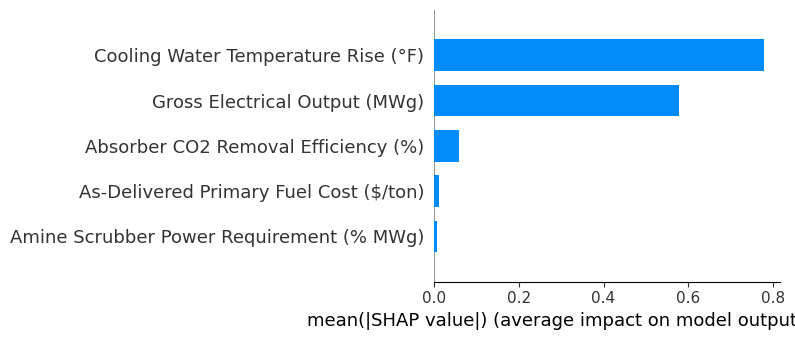

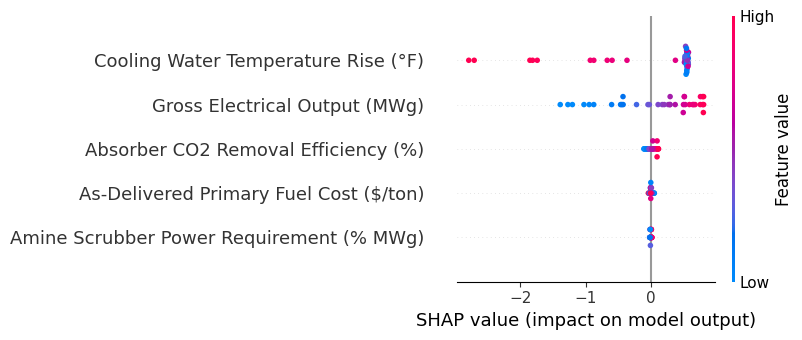

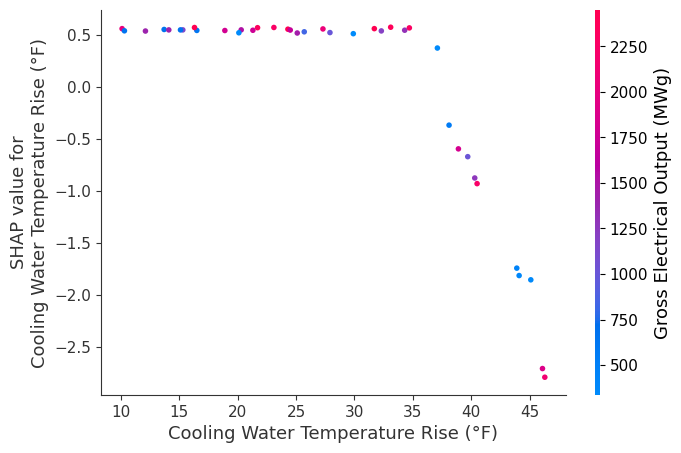

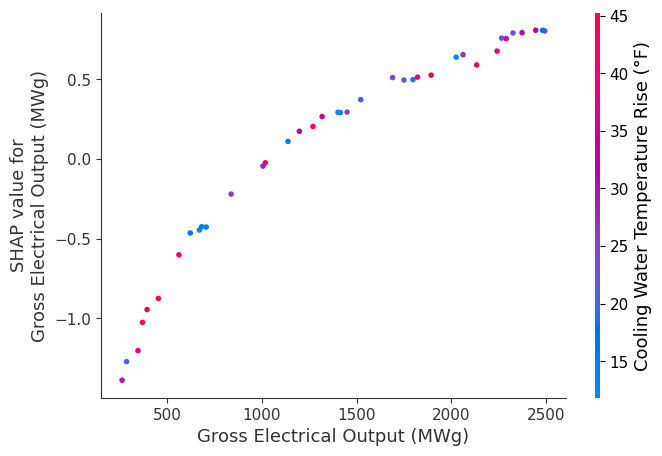

In [14]:
import shap, numpy as np
explainer   = shap.TreeExplainer(best_gbr)
shap_values = explainer.shap_values(x_test)

shap.summary_plot(shap_values, x_test, plot_type="bar")
shap.summary_plot(shap_values, x_test)

mean_abs = np.abs(shap_values).mean(axis=0)
order    = np.argsort(mean_abs)[::-1]
for i in order[:2]:
    shap.dependence_plot(x_test.columns[i], shap_values, x_test)